-*- encoding: utf-8 -*-
This file is part of GaPSE
Copyright (C) 2022 Matteo Foglieni
GaPSE is free software: you can redistribute it and/or modify
it under the terms of the GNU General Public License as published by
the Free Software Foundation, either version 3 of the License, or
(at your option) any later version.
GaPSE is distributed in the hope that it will be useful, but
WITHOUT ANY WARRANTY; without even the implied warranty of
MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the GNU
General Public License for more details.
You should have received a copy of the GNU General Public License
along with GaPSE. If not, see <http://www.gnu.org/licenses/>.

# threads_scaling

How much faster GaPSE gets when Julia is given more than one thread, measured rather than
asserted.

The parallel path is a single function, `map_over_ss` in `src/OtherUtils.jl`: the four
`map_ξ_*_multipole` spread their $s$ values over the default thread pool with
`Threads.@threads :dynamic`. Each $s$ is its own quadrature over $\mu$ and the `Cosmology`
is read-only on that path, so the points are independent; the scheduling is `:dynamic`
because the cost of one $s$ grows with $s$ and a static split would leave one thread
running alone on the far end of the grid.

**A notebook cannot change its own thread count.** `JULIA_NUM_THREADS` is read once, when
the kernel process starts, and `Threads.nthreads()` is fixed from then on - there is no
API to resize the pool. So the only way to compare thread counts from here is to start one
Julia process per count. This notebook writes a small worker script into
`threads_scaling/` and runs it with `-t 1`, `-t 2`, ... through `run()`.

(In IJulia the shell escape is `;` at the start of a line, not the `!` of IPython:
`;julia -t 2 worker.jl` would work too. `run()` is used instead because it is plain Julia -
it works in any kernel and in a plain REPL - and because the exit status and the output
come back as values.)

What is timed is `map_ξ_GNC_multipole` for `auto_lensing`, one of the heaviest effects and
one whose per-point cost grows with $s$, at $L = 0$ and with the settings of the unit
tests. The `Cosmology` build and the JIT warm-up happen before the clock starts, so what
is measured is the parallel loop and nothing else.

All the output files are saved in the `threads_scaling/` directory.

In [1]:
"""
    help(x)

Show the docstring of `x`. Useful in VSCode or Jupyter Lab, where prepending `?` doesn't work.
"""
macro help(x)
    quote
        display("text/markdown", @doc $x)
    end
end;
@help @help

```julia
help(x)
```

Show the docstring of `x`. Useful in VSCode or Jupyter Lab, where prepending `?` doesn't work.


## GaPSE setup

In [2]:
using GaPSE
using Plots, LaTeXStrings, DelimitedFiles, Printf
# GR, the default Plots backend: it needs no Python at all, and it is the one that
# works under Julia 1.12 - see the "Which backend" section of ../ipynbs/README.md
gr()

Plots.GRBackend()

In [3]:
const PATH_TO_GAPSE = normpath(joinpath(@__DIR__, ".."));
const DIR = joinpath(@__DIR__, "threads_scaling");
@assert isdir(DIR) "ERROR: DIR=$DIR DOESN'T EXIST!!!"

# the environment the worker processes have to run in: this one
const PROJECT = @__DIR__;
# the julia binary this kernel is running, WITHOUT any thread flag: `Base.julia_cmd()`
# carries `-C`, `-J` and `-g`, but not `--threads`, so `-t` can be appended freely
const JULIA = Base.julia_cmd();

In [4]:
# How many threads this kernel got, and how many the machine has.
@printf("Threads.nthreads() of this kernel : %d\n", Threads.nthreads())
@printf("Sys.CPU_THREADS                   : %d\n", Sys.CPU_THREADS)

# The scan stops at 4 threads: it is enough to see the shape, and it keeps the notebook
# to a few minutes. Raise it if you like - but never above `Sys.CPU_THREADS`, because
# past that Julia does not clamp, it really starts the threads, and all that is measured
# from there on is the scheduler.
const THREAD_COUNTS = collect(1:min(4, Sys.CPU_THREADS));

# --- scan 1: one effect, several sizes of the `s` grid ------------------------
# 3 is not an arbitrary small number: it is what every `*_specific_ss.txt` of the test
# suite contains, i.e. what the unit tests actually give the parallel loop
const N_SS = [3, 16, 64, 256];
const EFFECT = "auto_lensing";

# --- scan 2: every GNC effect, one size of the `s` grid -----------------------
const EFFECTS_ALL = GaPSE.GR_EFFECTS_GNC;
const N_SS_ALL = 256;

const N_REP = 3;

# the two results files, both written into `threads_scaling/`
const FILE_ONE = "times.txt";
const FILE_ALL = "times_effects.txt";


Threads.nthreads() of this kernel : 1
Sys.CPU_THREADS                   : 8


## The worker script

One process per thread count. The script is written here, so that this notebook stays the
only source: editing the cell below and re-running it replaces `threads_scaling/worker.jl`.

In [5]:
@help grid

```julia
grid(args...; kw...)
```

Create a grid layout for subplots. `args` specify the dimensions, e.g. `grid(3,2, widths = (0.6,0.4))` creates a grid with three rows and two columns of different width.


In [6]:
const WORKER_SRC = raw"""
# Written by theory/threads_scaling.ipynb - do not edit by hand.
#
# One process of the scaling study: it builds the Cosmology, warms the JIT up, and only
# then times `map_ξ_GNC_multipole`, i.e. the function that `map_over_ss` parallelises.
#
# usage:  julia -t <N> --project=<theory> worker.jl <outdir> <outfile> <n_ss> <effect...>
#
#   <outdir>   : where to append the results
#   <outfile>  : name of the file to append to
#   <n_ss>     : comma separated sizes of the `s` grid, e.g. "3,16,64,256"
#   <effect>   : one or more GNC effect names
#
# It appends one row per (effect, n_ss) pair
#
#     threads   effect   n_ss   time[s]
#
# and, when a single effect is asked for, it also writes the whole `ξ` of the largest
# grid to `xis_<N>threads.txt`, so that the results of different thread counts can be
# compared digit by digit.

using GaPSE, Printf

const OUTDIR = abspath(ARGS[1])
const OUTFILE = ARGS[2]
const N_SS = parse.(Int, split(ARGS[3], ','))
const EFFECTS = ARGS[4:end]
const NT = Threads.nthreads()
const N_REP = 3
const PATH_TO_GAPSE = normpath(joinpath(@__DIR__, "..", ".."))

params = GaPSE.CosmoParams(0.05, 0.20, pi / 2.0;
    Ω_b = 0.0489, Ω_cdm = 0.251020, 
    h_0 = 0.70, s_lim = 1e-2, z_spline_lim = 1000.0,
    b1 = 1.0, s_b1 = 0.0, 𝑓_evo1 = 0.0, 
    b2 = nothing, s_b2 = nothing, 𝑓_evo2 = nothing,
    IPS_opts = Dict(
        :fit_left_min => 1e-6, :fit_left_max => 3e-6,
        :fit_right_min => 1e1, :fit_right_max => 2e1),
    IPSTools_opts = Dict(
        :N => 1024, :fit_min => 0.05, :fit_max => 0.5, 
        :con => true, :k_min => 1e-8, :k_max => 10.0),
);

COSMO = GaPSE.Cosmology(
    params,
    joinpath(PATH_TO_GAPSE, "data", "WideA_ZA_background.dat"),
    joinpath(PATH_TO_GAPSE, "data", "WideA_ZA_pk.dat"),
    joinpath(PATH_TO_GAPSE, "data", "F_REFERENCE_pi2.txt"),
    joinpath(PATH_TO_GAPSE, "data", "IntegrF_REFERENCE_pi2_z005020.txt")
);

const BASE_KW = Dict(
    :use_windows => false, :enhancer => 1e8, 
    :obs => :noobsvel,
    :N_trap => 30, :N_lob => 30, :N_χs => 40, :N_χs_2 => 20,
    :suit_sampling => false, :alg => :lobatto
);

# NOTE `pr = false`: the ProgressMeter is thread-safe by taking a lock as soon as it is
# advanced from more than one thread, which is exactly the kind of serialisation that a
# threading benchmark must not measure. The progress bars would go to /dev/null anyway,
# `run_scan` piping the worker's stdout there.
run_map(eff, kw, v_ss) = GaPSE.map_ξ_GNC_multipole(COSMO, eff, v_ss; L=0, pr=false, kw...)[2]

grid(n) = 10 .^ range(0, log10(2 * COSMO.s_max), length=n)

open(joinpath(OUTDIR, OUTFILE), "a") do io
    for eff in EFFECTS
        kw = GaPSE.specif_kwargs_GNC(eff, BASE_KW)
        run_map(eff, kw, grid(4))   # warm-up: everything below is measured on compiled code
        for n in N_SS
            v_ss = grid(n)
            xis = run_map(eff, kw, v_ss)
            t = minimum([(s = time(); run_map(eff, kw, v_ss); time() - s) for _ in 1:N_REP])
            @printf(io, "%3d %24s %6d %14.6f\n", NT, eff, n, t)
            flush(io)
            if length(EFFECTS) == 1 && n == maximum(N_SS)
                open(joinpath(OUTDIR, "xis_$(NT)threads.txt"), "w") do f
                    for x in xis
                        @printf(f, "%.17g\n", x)
                    end
                end
            end
        end
    end
end
println("worker done: nthreads = ", NT)
""";

const WORKER = joinpath(DIR, "worker.jl");
write(WORKER, WORKER_SRC);
println("written $(WORKER)  ($(length(split(WORKER_SRC, '\n'))) lines)")


written /Users/di75tom/AAA_TESI_MAGISTRALE/GaPSE_CODING/GaPSE-worktree/threads/theory/threads_scaling/worker.jl  (88 lines)


## Running the scan, and reading it back

In [7]:
"""
    write_hardware_header(io; kwargs...)

Write, as `#` comments at the top of a results file, what the machine and the settings
were. A wall time means nothing without them, and a file of numbers outlives the session
that produced it.
"""
function write_hardware_header(io; effects, n_ss, thread_counts)
    info = Sys.cpu_info()
    println(io, "# GaPSE - theory/threads_scaling.ipynb")
    println(io, "# date             : ", Libc.strftime("%Y-%m-%d %H:%M:%S %Z", time()))
    println(io, "#")
    println(io, "# --- hardware and runtime, from Sys.cpu_info() and friends ---")
    println(io, "# cpu model        : ", info[1].model)
    @printf(io, "# cpu speed        : %d MHz (as reported for core #1)\n", info[1].speed)
    println(io, "# length(cpu_info) : ", length(info))
    println(io, "# Sys.CPU_NAME     : ", Sys.CPU_NAME)
    println(io, "# Sys.CPU_THREADS  : ", Sys.CPU_THREADS)
    println(io, "# Sys.MACHINE      : ", Sys.MACHINE)
    println(io, "# Sys.KERNEL       : ", Sys.KERNEL)
    @printf(io, "# total memory     : %.1f GiB\n", Sys.total_memory() / 2^30)
    println(io, "# julia            : ", VERSION)
    println(io, "# BLAS             : ", GaPSE.LinearAlgebra.BLAS.get_num_threads(), " threads")
    println(io, "# JULIA_NUM_THREADS: ", get(ENV, "JULIA_NUM_THREADS", "/"), "   (of this kernel; the workers get -t explicitly)")
    println(io, "# OMP_NUM_THREADS  : ", get(ENV, "OMP_NUM_THREADS", "/"))
    println(io, "#")
    println(io, "# --- what was measured ---")
    println(io, "# thread counts    : ", thread_counts)
    println(io, "# s grid sizes     : ", n_ss)
    println(io, "# repetitions      : ", N_REP, "   (the minimum is kept)")
    println(io, "# effects          : ", length(effects) == 1 ? only(effects) : "$(length(effects)) of them, GaPSE.GR_EFFECTS_GNC")
    println(io, "#")
    println(io, "# threads", " "^18, "effect   n_ss        time[s]")
    nothing
end;

"""
    run_scan(outfile; effects, n_ss, thread_counts=THREAD_COUNTS)

Run one worker process per entry of `thread_counts`, appending to
`threads_scaling/<outfile>`. The old results are deleted first, so the file always holds
exactly one scan, under the hardware header written here.

Each process pays for its own `Cosmology` build and JIT warm-up before it times anything,
so a scan takes minutes rather than seconds.
"""
function run_scan(outfile; effects, n_ss, thread_counts=THREAD_COUNTS)
    rm(joinpath(DIR, outfile), force=true)
    length(effects) == 1 && foreach(f -> rm(joinpath(DIR, f), force=true),
        filter(f -> startswith(f, "xis_") && endswith(f, "threads.txt"), readdir(DIR)))
    open(joinpath(DIR, outfile), "w") do io
        write_hardware_header(io; effects=effects, n_ss=n_ss, thread_counts=thread_counts)
    end
    ns = join(string.(n_ss), ',')
    for t in thread_counts
        cmd = `$JULIA -t $t --project=$PROJECT $WORKER $DIR $outfile $ns $effects`
        @printf("-t %-3d ... ", t)
        el = @elapsed run(pipeline(cmd, stdout=devnull))
        @printf("done in %6.1f s (build + JIT + %d timed runs)\n",
            el, length(n_ss) * length(effects) * N_REP)
    end
    nothing
end;


In [8]:
"""
    read_times(file) :: Matrix

A results file as a matrix, one row per `(threads, effect, n_ss)`: threads, effect name,
n_ss, seconds. `comments=true` skips the hardware header.
"""
read_times(file) = readdlm(joinpath(DIR, file), comments=true);

"""
    times_of(tab, effect, n) :: Vector{Float64}

The wall times of `effect` on the grid of `n` points, ordered as `THREAD_COUNTS`.
"""
times_of(tab, effect, n) =
    [tab[findfirst(i -> tab[i, 1] == t && tab[i, 2] == effect && tab[i, 3] == n,
         axes(tab, 1)), 4] for t in THREAD_COUNTS];

"""
    speedups_of(tab, effect, n) :: Vector{Float64}

`t_1 / t_N` of `effect` on the grid of `n` points, ordered as `THREAD_COUNTS`.
"""
function speedups_of(tab, effect, n)
    ts = times_of(tab, effect, n)
    ts[1] ./ ts
end;


In [9]:
"""
    table_times(io=stdout; file=FILE_ONE, effect=EFFECT, n_ss=N_SS)

Wall time, speedup against one thread, and parallel efficiency, for every grid size.
"""
function table_times(io=stdout; file=FILE_ONE, effect=EFFECT, n_ss=N_SS)
    tab = read_times(file)
    for n in n_ss
        ts = times_of(tab, effect, n)
        @printf(io, "\n%s, %d points on the s grid\n", effect, n)
        @printf(io, "  %8s %12s %10s %12s\n", "threads", "time [s]", "speedup", "efficiency")
        for (k, t) in enumerate(THREAD_COUNTS)
            @printf(io, "  %8d %12.4f %10.2fx %11.0f%%\n",
                t, ts[k], ts[1] / ts[k], 100 * (ts[1] / ts[k]) / t)
        end
    end
end;

"""
    table_effects(io=stdout; file=FILE_ALL, n=N_SS_ALL)

One row per GNC effect: the wall time at each thread count and the speedup at the largest
one, sorted by the single-thread time, so that the effects that actually cost something
come first.
"""
function table_effects(io=stdout; file=FILE_ALL, n=N_SS_ALL)
    tab = read_times(file)
    rows = [(eff, times_of(tab, eff, n)) for eff in EFFECTS_ALL]
    sort!(rows, by=r -> -r[2][1])
    @printf(io, "\n%d GNC effects, %d points on the s grid\n", length(rows), n)
    @printf(io, "  %-22s", "effect")
    for t in THREAD_COUNTS
        @printf(io, " %11s", "t($(t)) [s]")
    end
    @printf(io, " %10s %12s\n", "speedup", "efficiency")
    for (eff, ts) in rows
        @printf(io, "  %-22s", eff)
        for x in ts
            @printf(io, " %11.4f", x)
        end
        @printf(io, " %9.2fx %11.0f%%\n",
            ts[1] / ts[end], 100 * (ts[1] / ts[end]) / THREAD_COUNTS[end])
    end
    tot = [sum(r[2][k] for r in rows) for k in eachindex(THREAD_COUNTS)]
    @printf(io, "  %-22s", "ALL OF THEM")
    for x in tot
        @printf(io, " %11.4f", x)
    end
    @printf(io, " %9.2fx %11.0f%%\n",
        tot[1] / tot[end], 100 * (tot[1] / tot[end]) / THREAD_COUNTS[end])
end;


In [10]:
"""
    check_identical(io=stdout)

Compare, digit by digit, the `ξ` of the largest grid as every thread count produced it.
`map_over_ss` writes each result into its own slot of a pre-allocated vector and the
`Cosmology` is only read, so the answer must not depend on how the points were split.
"""
function check_identical(io=stdout)
    files = sort(filter(f -> startswith(f, "xis_") && endswith(f, "threads.txt"), readdir(DIR)))
    vals = Dict(f => readdlm(joinpath(DIR, f))[:, 1] for f in files)
    ref = first(files)
    @printf(io, "%-24s %8s %28s\n", "file", "n", "max |x - x_ref| / |x_ref|")
    for f in files
        d = maximum(abs.((vals[f] .- vals[ref]) ./ vals[ref]))
        @printf(io, "%-24s %8d %28s\n", f, length(vals[f]),
            d == 0 ? "0  (bit for bit)" : @sprintf("%.3e", d))
    end
    nothing
end;

## Plot functions

In [11]:
function plot_kwargs(kwargs...)
    dict_defaults = Dict(
        :size => (1000, 400), :dpi => 300, :legendposition => :outerright,
        :legendfontsize => 11, :guidefontsize => 14, :tickfontsize => 11,
        :titlefontsize => 16, :left_margin => 10Plots.mm,
    )
    # In "merge", if a key is repeated in the input dicts, the LAST collection value has priority
    merge(dict_defaults, Dict(kwargs))
end;
func_linecolor(i::Int) = i>0 ? [:green, :orange, :blue, :red, :cyan, :grey, :black][(i-1)%7+1] : throw(AssertionError("only positive integers allowed"));
func_markershape(i::Int) = i>0 ? [:circle, :dtriangle, :diamond, :rect][(i-1)%4+1] : throw(AssertionError("only positive integers allowed"));
"""
    effect_latex(effect::AbstractString) :: LaTeXString

The LaTeX symbol of a GNC effect, the same convention as the notebooks in `../ipynbs`:
`"auto_lensing"` becomes ``\\kappa \\, \\kappa``, `"newton_integratedgp"` becomes
``\\delta \\, \\int\\phi``. Far more compact than the name on a crowded axis, and it is
what the rest of the project draws.
"""
const SYMBOL_OF_GR_TERM = Dict(
    "newton" => raw"\delta",
    "doppler" => raw"v_{\parallel}",
    "lensing" => raw"\kappa",
    "localgp" => raw"\phi",
    "integratedgp" => raw"\int\phi",
);
function effect_latex(effect::AbstractString)
    a, b = split(effect, '_')
    a == "auto" && (a = b)
    for s in (a, b)
        haskey(SYMBOL_OF_GR_TERM, s) || throw(ArgumentError(
            "no LaTeX symbol known for the GR term \"$s\" of the effect \"$effect\""))
    end
    latexstring(SYMBOL_OF_GR_TERM[a] * raw" \, " * SYMBOL_OF_GR_TERM[b])
end;


In [12]:
logticks(lo, hi; step=1) = 10.0 .^ (floor(Int, log10(lo)):step:ceil(Int, log10(hi)))

logticks (generic function with 1 method)

In [13]:
function save_plot(p, name)
    savefig(p, joinpath(DIR, name))
    nothing
end

save_plot (generic function with 1 method)

In [14]:
"""
    plot_times(; kwargs...)

Wall time of `map_ξ_GNC_multipole` against the number of threads, one curve per grid size.
"""
function plot_times(; kwargs...)
    tab = read_times(FILE_ONE)
    p = plot(; yscale=:log10,
        xlabel="number of threads", ylabel=L"t \; [\mathrm{s}]" * " "^6,
        title="Wall time of " * L"\xi^{\,\mathrm{GNC}}_{\kappa \kappa}" * ", " * L"L=0",
        yguidefontrotation=-90, xticks=THREAD_COUNTS,
        plot_kwargs(:left_margin => 22Plots.mm, :bottom_margin => 8Plots.mm, kwargs...)...)
    for (j,n) in enumerate(N_SS)
        plot!(p, THREAD_COUNTS, times_of(tab, EFFECT, n), 
            lw=2, lc=func_linecolor(j), 
            marker=func_markershape(j), ms=4, mc=func_linecolor(j), markerstrokewidth=0,
            label="$n points")
    end
    p
end;

In [15]:
"""
    plot_speedup(; kwargs...)

Speedup and parallel efficiency against the number of threads. The dashed line is the
ideal one; a curve that flattens is a grid too short to keep the threads busy.
"""
function plot_speedup(; kwargs...)
    tab = read_times(FILE_ONE)
    p1 = plot(; xlabel="number of threads", ylabel=L"\frac{t_1}{t_N}" * " "^1,
        title="Speedup", yguidefontrotation=-90, xticks=THREAD_COUNTS,
        plot_kwargs(:left_margin => 15Plots.mm, :bottom_margin => 8Plots.mm,
            :size => (1000, 340), kwargs...)...)
    plot!(p1, THREAD_COUNTS, THREAD_COUNTS, ls=:dash, lw=2, c=:gray, label="ideal")
    for (j,n) in enumerate(N_SS)
        ts = times_of(tab, EFFECT, n)
        plot!(p1, THREAD_COUNTS, ts[1] ./ ts, 
            lw=2, lc=func_linecolor(j), 
            marker=func_markershape(j), ms=4, mc=func_linecolor(j), markerstrokewidth=0,
            label="$n points")
    end
    p2 = plot(; xlabel="number of threads", ylabel=L"\frac{1}{N} \; \frac{t_1}{t_N}" * " "^1,
        title="Parallel efficiency", yguidefontrotation=-90, xticks=THREAD_COUNTS,
        ylims=(0, 1.15),
        plot_kwargs(:left_margin => 15Plots.mm, :bottom_margin => 8Plots.mm,
            :size => (1000, 340), kwargs...)...)
    hline!(p2, [1.0], ls=:dash, lw=2, c=:gray, label="ideal")
    for (j,n) in enumerate(N_SS)
        ts = times_of(tab, EFFECT, n)
        plot!(p2, THREAD_COUNTS, (ts[1] ./ ts) ./ THREAD_COUNTS, 
            lw=2, lc=func_linecolor(j), 
            marker=func_markershape(j), ms=4, mc=func_linecolor(j), markerstrokewidth=0,
            label="$n points")
    end
    plot(p1, p2; layout=(2, 1), size=(1000, 700), dpi=300)
end;

In [16]:
"""
    plot_effects(; file=FILE_ALL, n=N_SS_ALL, kwargs...)

Every GNC effect at once, sorted by its single-thread wall time. Above, what each effect
costs on one thread - which is the thing that decides whether its speedup matters at all;
below, the speedup each of them gets, one series per thread count.
"""
function plot_effects(; file=FILE_ALL, n=N_SS_ALL, kwargs...)
    tab = read_times(file)
    rows = sort([(eff, times_of(tab, eff, n)) for eff in EFFECTS_ALL], by=r -> -r[2][1])
    effs = [r[1] for r in rows]
    xs = eachindex(effs)
    ticks = (collect(xs), effect_latex.(effs))

    p1 = plot(; yscale=:log10, ylabel=L"t_1 \; [\mathrm{s}]" * " "^4,
        title="Cost of one evaluation, on a single thread, " * L"N_s = %$n",
        yguidefontrotation=-90, xticks=(collect(xs), fill("", length(effs))),
        plot_kwargs(:left_margin => 18Plots.mm, :bottom_margin => 2Plots.mm,
            :size => (1400, 300), :right_margin => 30Plots.mm, :legendposition => :none, kwargs...)...)
    plot!(p1, xs, [r[2][1] for r in rows], lw=2, lc=func_linecolor(1), label="",
        marker=func_markershape(1), ms=4, mc=func_linecolor(1), markerstrokewidth=0)

    p2 = plot(; ylabel=L"\frac{t_1}{t_N}" * " "^1,
        title="Speedup of each effect", yguidefontrotation=-90, xticks=ticks,
        xrotation=45, ylims=(0, THREAD_COUNTS[end] + 0.4),
        plot_kwargs(:left_margin => 18Plots.mm, :bottom_margin => 8Plots.mm,
            :size => (1400, 420), kwargs...)...)
    hline!(p2, [THREAD_COUNTS[end]], ls=:dash, lw=2, c=:gray,
        label="ideal, " * L"N = %$(THREAD_COUNTS[end])")
    for (j, t) in enumerate(THREAD_COUNTS)
        t == 1 && continue
        plot!(p2, xs, [r[2][1] / r[2][j] for r in rows], lw=2, lc=func_linecolor(j),
            marker=func_markershape(j), ms=4, mc=func_linecolor(j), markerstrokewidth=0,
            label="$t threads")
    end
    plot(p1, p2; layout=grid(2, 1, heights=[0.38, 0.62]), size=(1400, 720), dpi=300)
end;

## 1. Run the scan

One Julia process per thread count. Most of the time below is the `Cosmology` build and
the JIT of each process, not the measurement.

In [17]:
run_scan(FILE_ONE; effects=[EFFECT], n_ss=N_SS)

-t 1   ... done in   26.4 s (build + JIT + 12 timed runs)
-t 2   ... done in   21.7 s (build + JIT + 12 timed runs)
-t 3   ... done in   21.2 s (build + JIT + 12 timed runs)
-t 4   ... done in   20.4 s (build + JIT + 12 timed runs)


## 2. Wall time, speedup, efficiency

In [18]:
table_times()


auto_lensing, 3 points on the s grid
   threads     time [s]    speedup   efficiency
         1       0.0079       1.00x         100%
         2       0.0055       1.44x          72%
         3       0.0028       2.78x          93%
         4       0.0029       2.76x          69%

auto_lensing, 16 points on the s grid
   threads     time [s]    speedup   efficiency
         1       0.0420       1.00x         100%
         2       0.0220       1.91x          96%
         3       0.0167       2.52x          84%
         4       0.0113       3.71x          93%

auto_lensing, 64 points on the s grid
   threads     time [s]    speedup   efficiency
         1       0.1707       1.00x         100%
         2       0.0884       1.93x          97%
         3       0.0618       2.76x          92%
         4       0.0455       3.75x          94%

auto_lensing, 256 points on the s grid
   threads     time [s]    speedup   efficiency
         1       0.6867       1.00x         100%
         2     

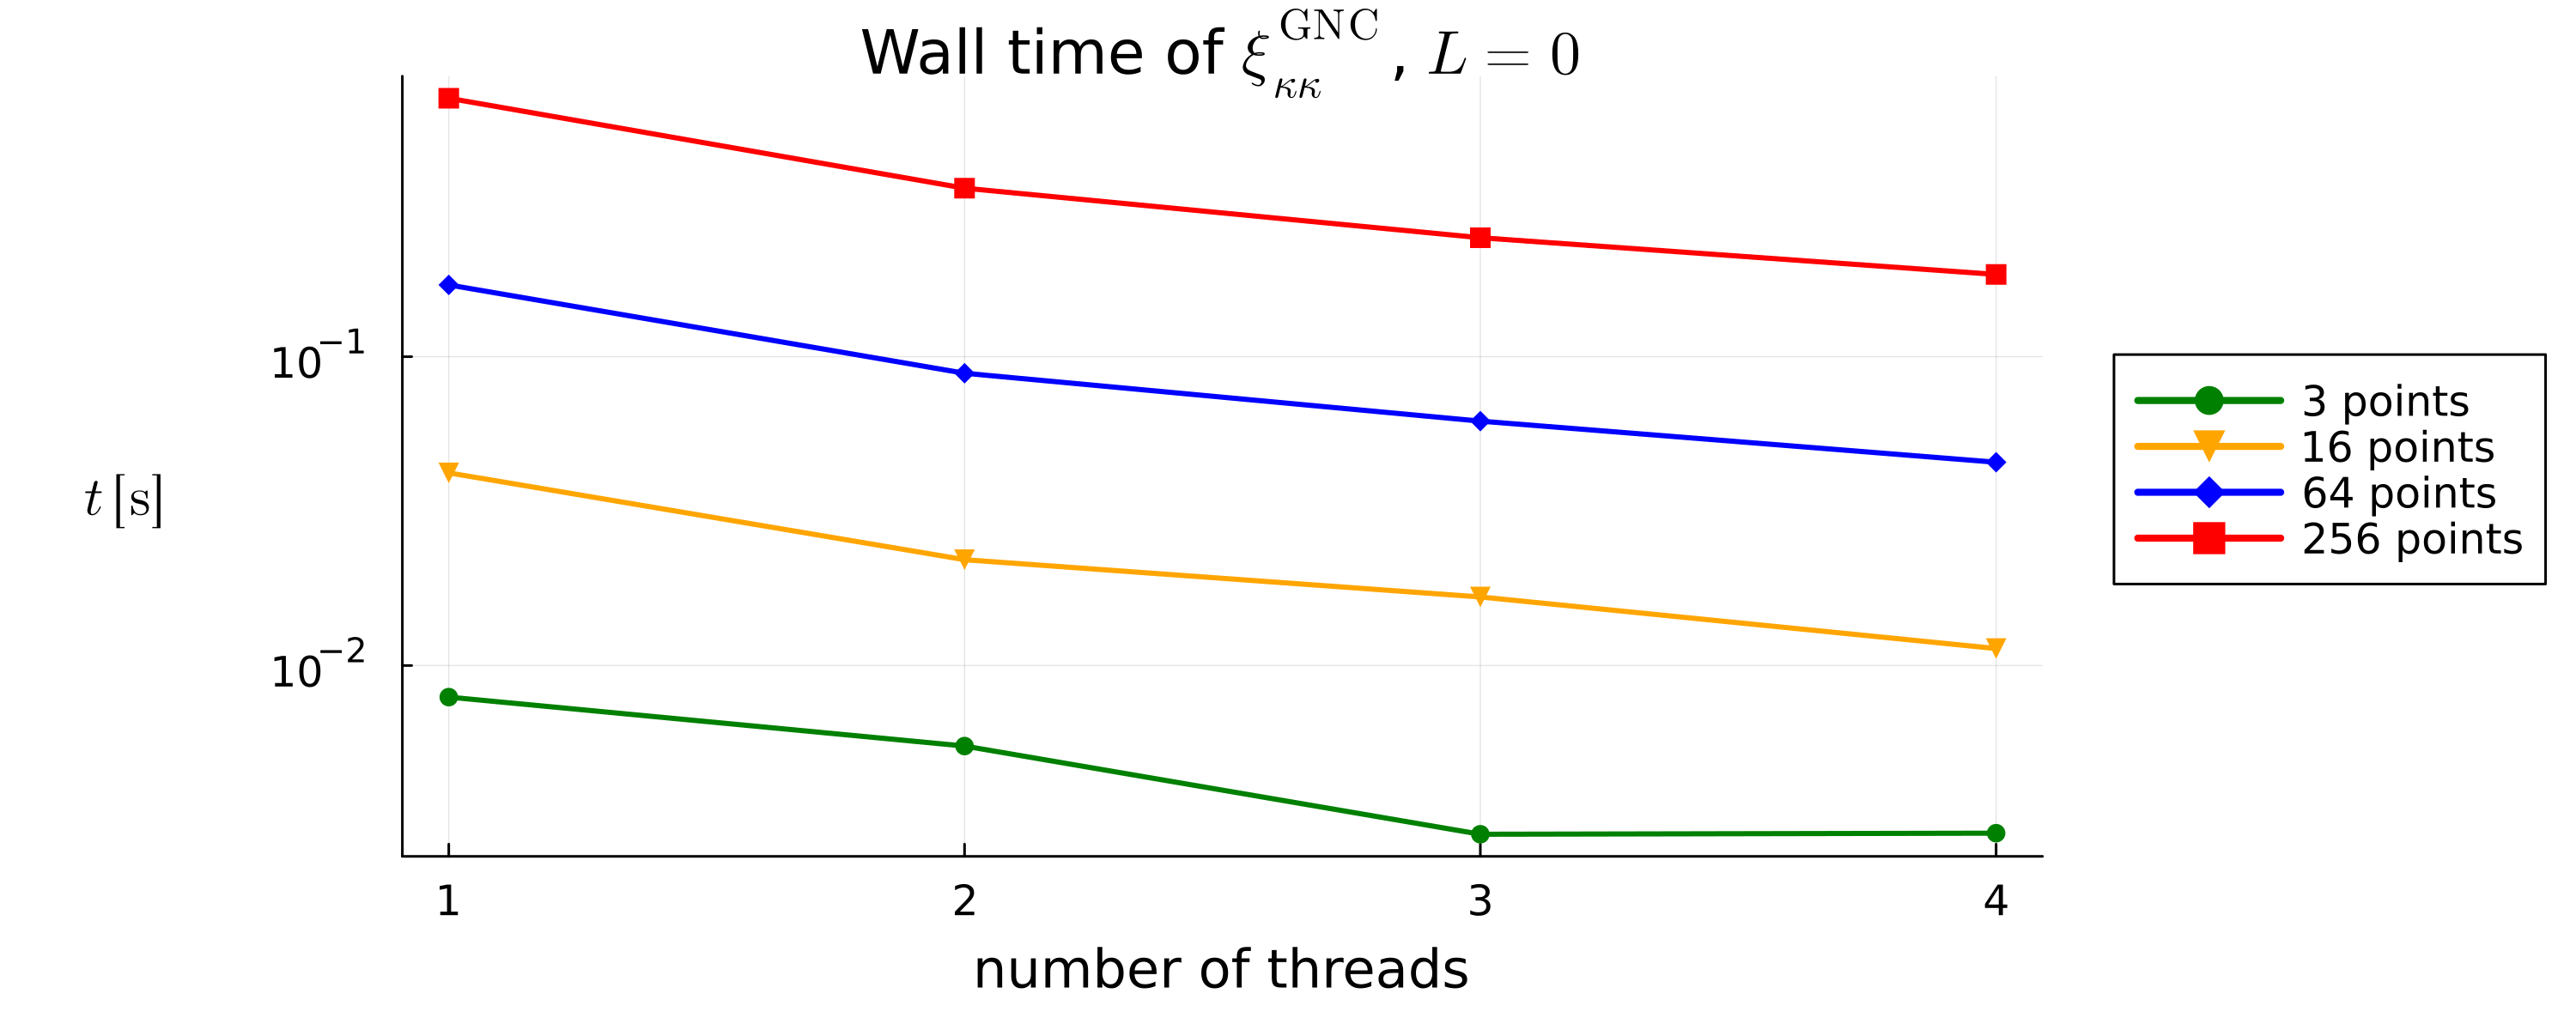

In [19]:
plot_times()

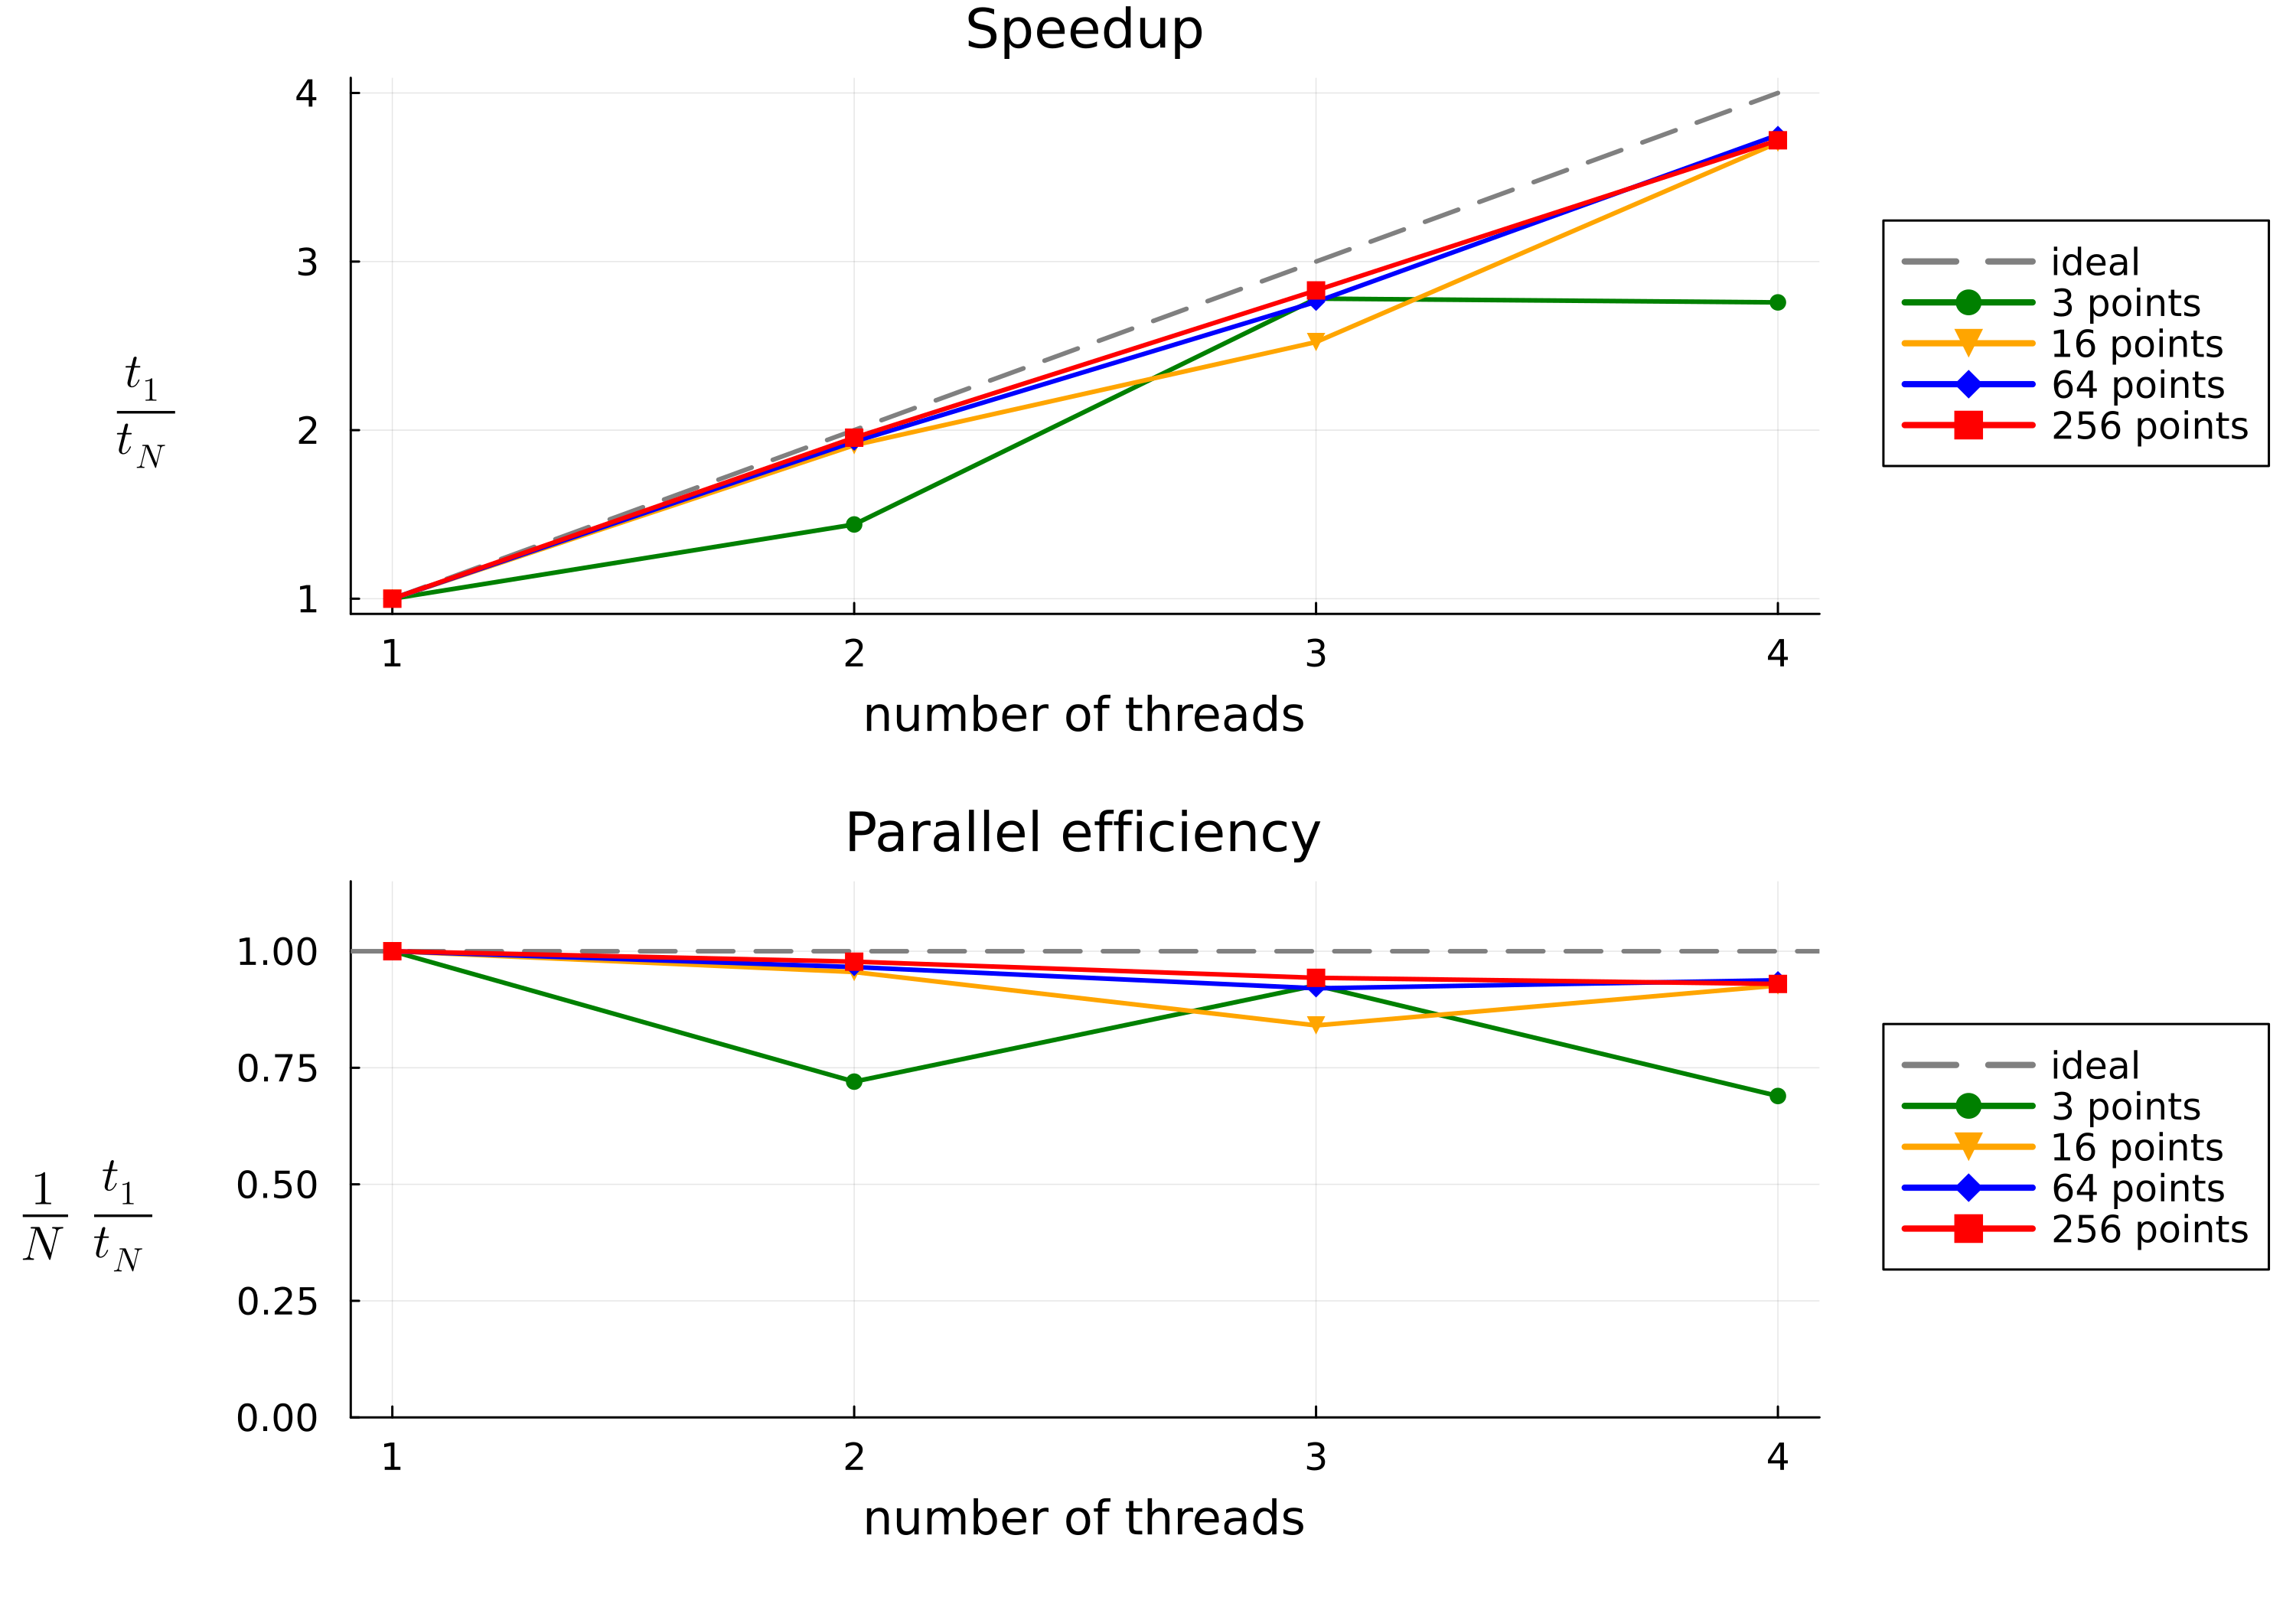

In [20]:
plot_speedup()

The 3-point curve is the one to look at. It follows the ideal line while there are threads
for it to use and then stops dead at 3, because `Threads.@threads` has only three tasks to
hand out: a fourth thread gets nothing, and the wall time becomes the cost of the slowest
single point. The larger grids keep climbing instead.

(These are minima over `N_REP` repetitions; on a shared or throttled machine a few percent
of jitter is normal, and a row that is not monotonic is noise rather than a result.)

It is tempting to read the 3-point curve as the explanation of why the 4-thread job of the
CI is not faster than the 1-thread one, since every `*_specific_ss.txt` of the test suite
holds exactly three $s$ values. **It is not the explanation**, and the plot above says so:
three points still buy close to a factor 3. The real reason is that those testsets barely
spend any time in this loop at all - `test GNC_SumXiMultipoles_P1` is 148 calls of the
*scalar* `sum_ξ_GNC_multipole`, which never reaches `map_over_ss`, plus 48 mapped calls,
about 10 s of arithmetic inside a 230 s testset. The other 220 s are compilation, which is
single-threaded whatever `-t` says. The three points only cap the ceiling of the part that
*can* be parallelised; they are not what makes the job slow.

So the 4-thread CI job earns its place as a *correctness* check, not a speed one - which
is what the next section is about.

## 3. The thread count changes nothing but the time

In [21]:
check_identical()

file                            n    max |x - x_ref| / |x_ref|
xis_1threads.txt              256             0  (bit for bit)
xis_2threads.txt              256             0  (bit for bit)
xis_3threads.txt              256             0  (bit for bit)
xis_4threads.txt              256             0  (bit for bit)


`map_over_ss` writes `xis[i] = f(v_ss[i])` into a pre-allocated vector, one slot per point,
and everything the closure reads from the `Cosmology` is immutable on this path
(`MySpline` is evaluated with `searchsortedlast`, `GridInterpolations.interpolate` keeps
its scratch in per-call `MVector`s). There is no accumulator and no shared buffer, so the
order in which the points complete cannot change their values - and it does not: the
numbers agree to all 17 digits written out.

## 4. All the effects, not just one

Everything above is `auto_lensing`, one of the heaviest. It is a fair thing to benchmark,
but it is not the whole answer: `map_over_ss` is the same loop for every effect, yet what
each effect does *inside* one point of the grid is not the same at all, and an effect that
costs a tenth of a millisecond per point has nothing to hide behind the overhead of
spawning the tasks.

So the same scan is repeated over all of `GaPSE.GR_EFFECTS_GNC`, at one size of the `s`
grid. One process per thread count again, but now each of them loops over the 25 effects
internally, so that the `Cosmology` build and most of the JIT are paid once instead of 25
times.

In [22]:
run_scan(FILE_ALL; effects=EFFECTS_ALL, n_ss=[N_SS_ALL])

-t 1   ... done in   45.8 s (build + JIT + 75 timed runs)
-t 2   ... done in   33.9 s (build + JIT + 75 timed runs)
-t 3   ... done in   31.2 s (build + JIT + 75 timed runs)
-t 4   ... done in   28.6 s (build + JIT + 75 timed runs)


Sorted by what each effect costs on one thread, the expensive ones first:

In [23]:
table_effects()


25 GNC effects, 256 points on the s grid
  effect                    t(1) [s]    t(2) [s]    t(3) [s]    t(4) [s]    speedup   efficiency
  auto_lensing                0.6835      0.3497      0.2426      0.1826      3.74x          94%
  integratedgp_lensing        0.4960      0.2525      0.1712      0.1295      3.83x          96%
  lensing_integratedgp        0.4919      0.2497      0.1739      0.1320      3.73x          93%
  auto_integratedgp           0.3796      0.1969      0.1374      0.1039      3.65x          91%
  doppler_integratedgp        0.1931      0.0865      0.0623      0.0460      4.20x         105%
  newton_integratedgp         0.1707      0.0886      0.0616      0.0457      3.73x          93%
  doppler_lensing             0.1698      0.0867      0.0613      0.0456      3.72x          93%
  lensing_doppler             0.1692      0.0879      0.0614      0.0470      3.60x          90%
  localgp_lensing             0.1676      0.0894      0.0579      0.0439      3.82x  

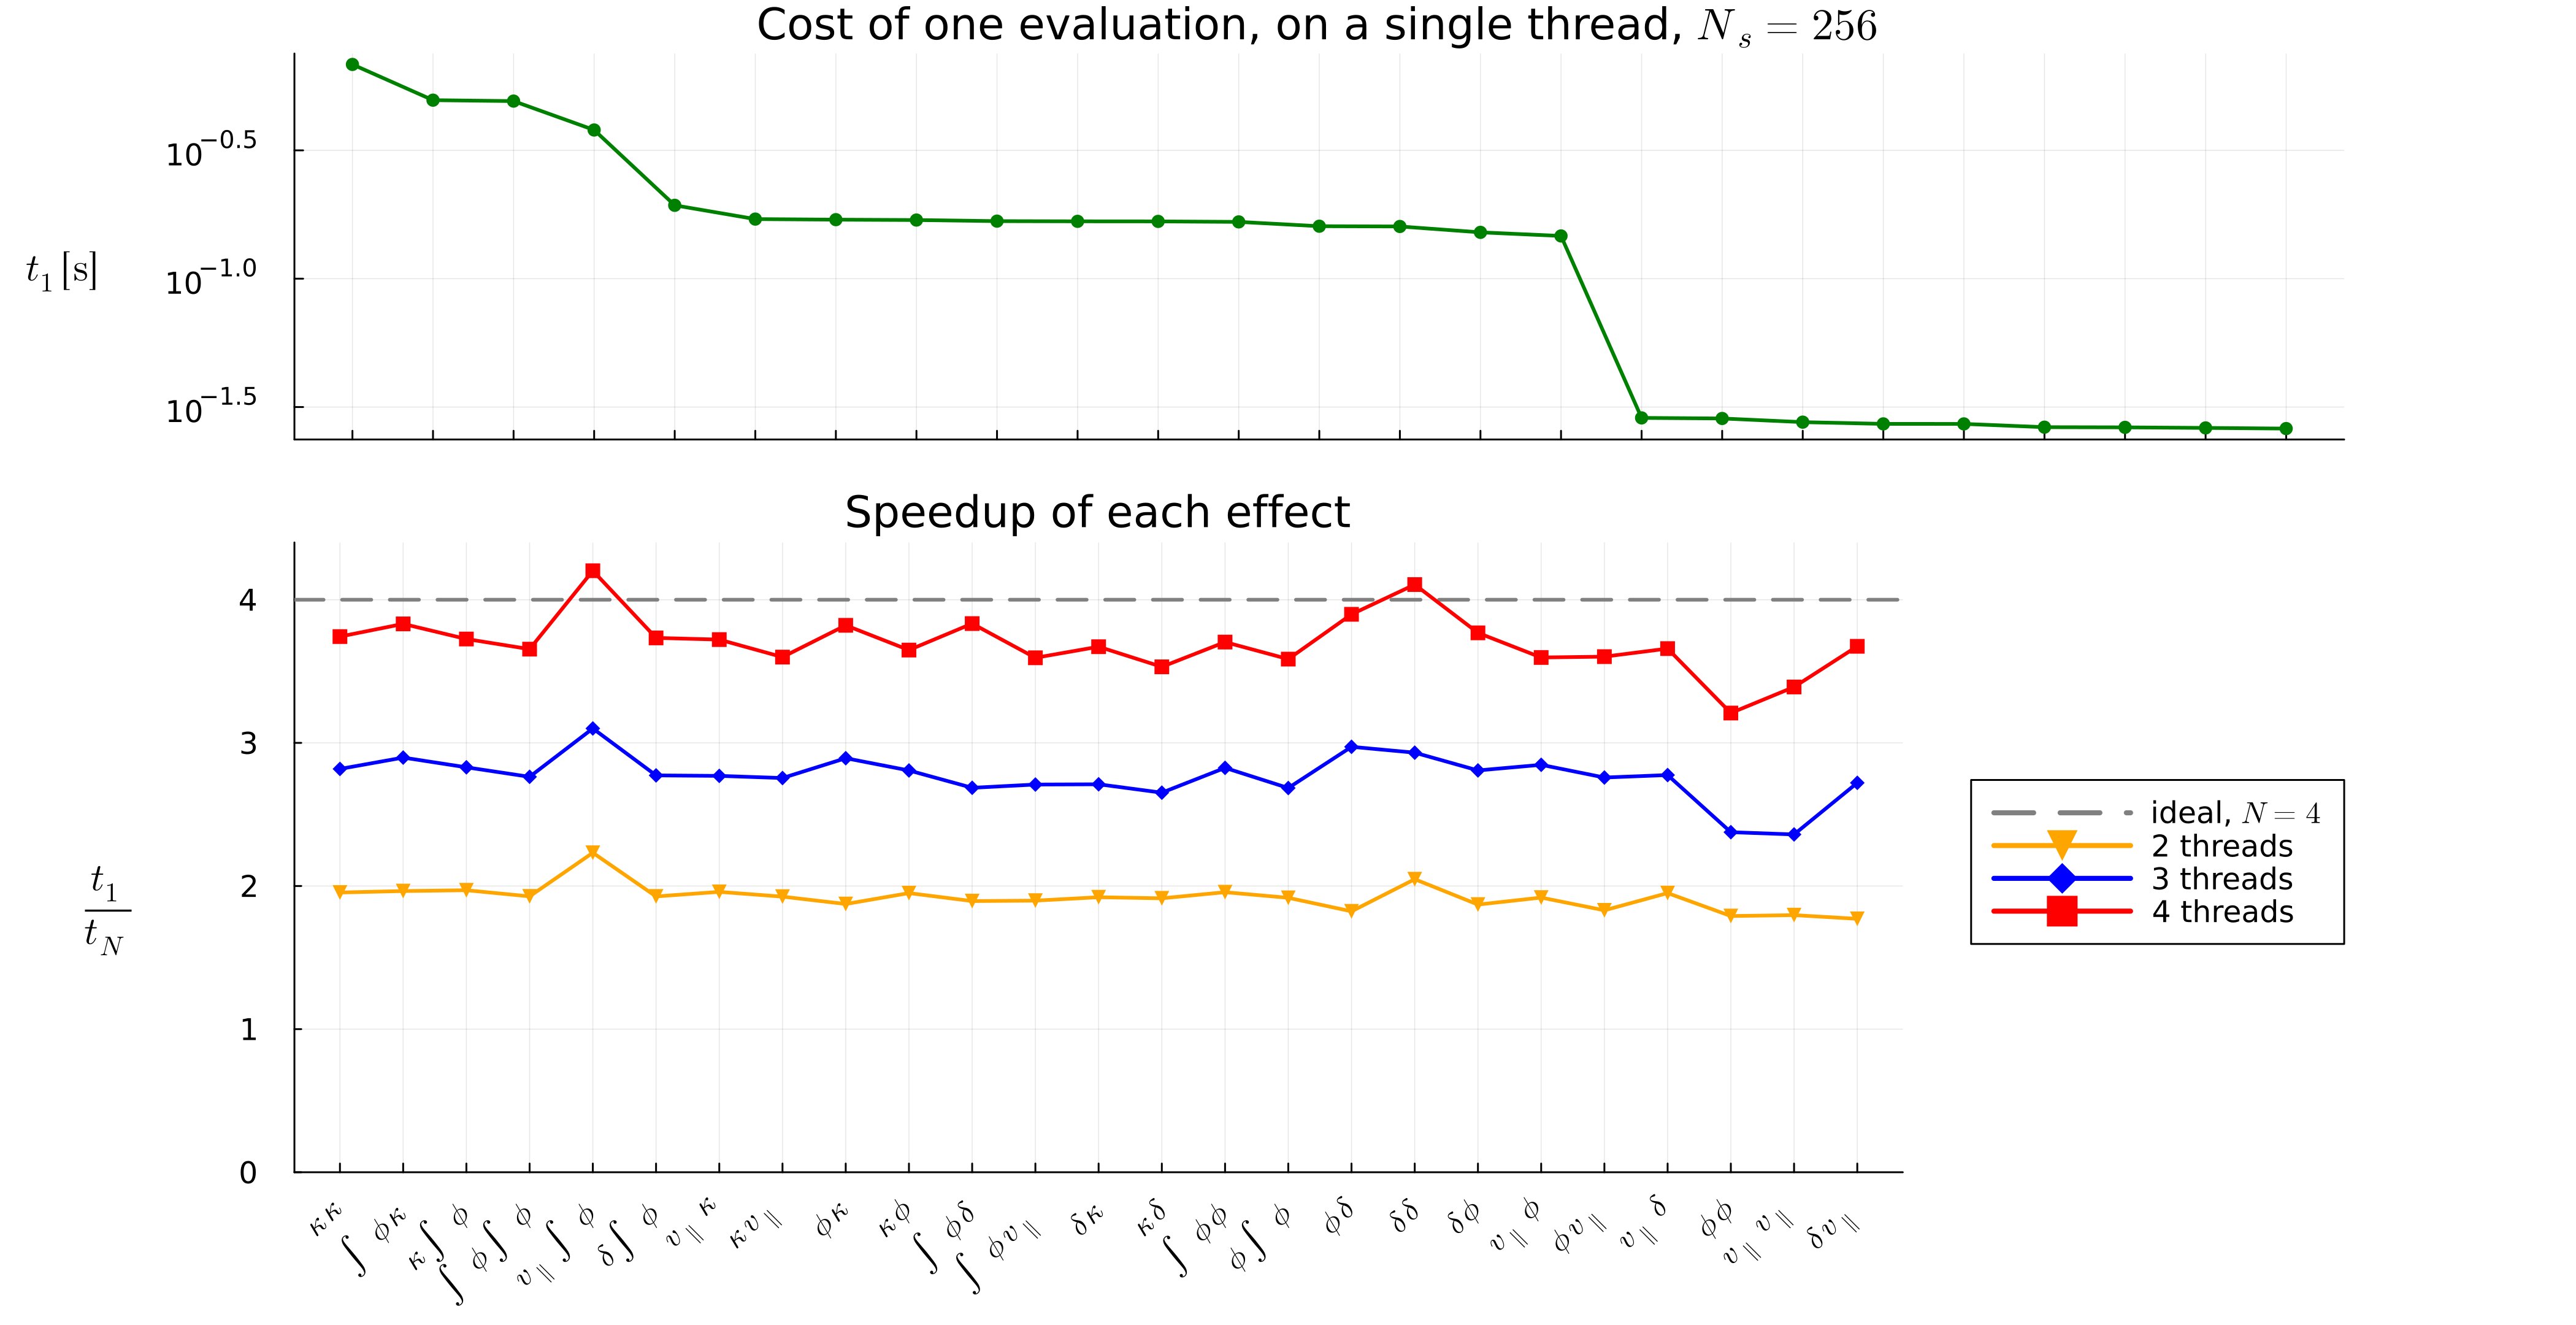

In [24]:
plot_effects()

The top panel spans a factor 30: a handful of effects - the ones with a lensing or
an integrated-gravitational-potential leg, which carry a `χ` integral inside every point -
dominate the cost, and the rest are almost free. The bottom panel is the one that matters
for a decision: an effect only reaches the ideal line if there is enough work per point to
cover the cost of handing it to another thread, so the cheap effects on the right sit well
below it while the expensive ones on the left do not.

That is the useful shape here. Parallelising helps exactly the effects that need it, and
the `ALL OF THEM` row of the table above - the sum, which is what `sum_ξ_GNC_multipole`
actually computes - inherits the speedup of the expensive ones, because they are what the
sum is made of.

## Save the plots and the data

In [25]:
save_plot(plot_times(), "threads_times.png");
save_plot(plot_speedup(), "threads_speedup.png");
save_plot(plot_effects(), "threads_effects.png");
open(joinpath(DIR, "threads_scaling_tables.txt"), "w") do io
    write_hardware_header(io; effects=EFFECTS_ALL, n_ss=N_SS, thread_counts=THREAD_COUNTS)
    table_times(io)
    println(io)
    table_effects(io)
    println(io)
    check_identical(io)
end
readdir(DIR)


12-element Vector{String}:
 ".ipynb_checkpoints"
 "threads_effects.png"
 "threads_scaling_tables.txt"
 "threads_speedup.png"
 "threads_times.png"
 "times.txt"
 "times_effects.txt"
 "worker.jl"
 "xis_1threads.txt"
 "xis_2threads.txt"
 "xis_3threads.txt"
 "xis_4threads.txt"

## END